<a href="https://colab.research.google.com/github/lekhasree15/BIS_LAB/blob/main/lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best Task Allocation: [ 1  4  5  1  0  3  6  1  0  5  7  9  5  2  3  9  6  0 10  7  4  3  0  9
 10 11  3 10 11  6  1  0  1  9  8  3  5  5  2 11  3  8  0 11  9  1  8  5
  3  5]
Best Fitness: 43.971968802816896
Makespan: 58.5712676056338
Total Cost: 29.372669999999996


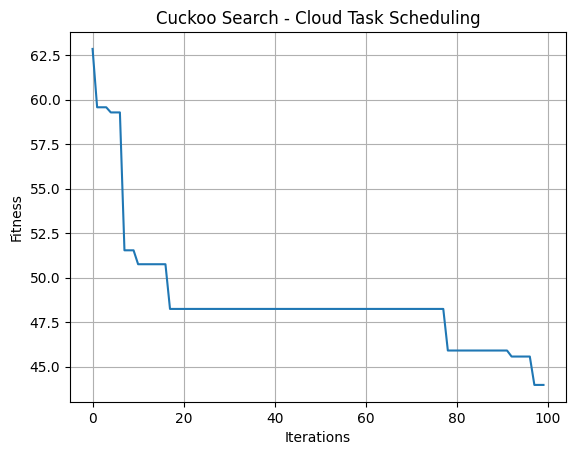

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
n_tasks = 50
n_vms = 12
n_nests = 25
iterations = 100
pa = 0.25
alpha = 0.4

np.random.seed(42)

# Generate tasks and VM resources
tasks = np.random.randint(10000, 100000, n_tasks)
mips = np.random.randint(1000, 10000, n_vms)
cost = mips / 100000

# Assign VMs to 4 clouds
clouds = np.arange(n_vms) % 4

# Fitness function
def fitness(solution):
    loads = np.zeros(n_vms)
    total_cost = 0

    for i, vm in enumerate(solution):
        time = tasks[i] / mips[vm]
        loads[vm] += time
        total_cost += time * cost[vm]

    makespan = max(loads)

    return 0.5 * makespan + 0.5 * total_cost, makespan, total_cost

# Lévy flight
def levy_flight():
    beta = 1.5
    sigma = 0.6966
    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)
    return u / abs(v)**(1/beta)

# Initialize nests
nests = np.random.randint(0, n_vms, (n_nests, n_tasks))

scores = np.array([fitness(x)[0] for x in nests])

best = nests[np.argmin(scores)].copy()
best_score = min(scores)

history = []

# Cuckoo Search
for t in range(iterations):

    for i in range(n_nests):

        new = nests[i].astype(float).copy()

        for j in range(n_tasks):
            new[j] += alpha * levy_flight() * (best[j] - new[j] + 1)

        new = np.clip(np.round(new), 0, n_vms - 1).astype(int)

        new_score = fitness(new)[0]

        if new_score < scores[i]:
            nests[i] = new
            scores[i] = new_score

    # Abandon worst nests
    worst = np.argsort(scores)[-int(pa * n_nests):]

    for i in worst:
        nests[i] = np.random.randint(0, n_vms, n_tasks)
        scores[i] = fitness(nests[i])[0]

    # Update best solution
    idx = np.argmin(scores)

    if scores[idx] < best_score:
        best = nests[idx].copy()
        best_score = scores[idx]

    history.append(best_score)

# Final results
score, makespan, total_cost = fitness(best)

print("Best Task Allocation:", best)
print("Best Fitness:", score)
print("Makespan:", makespan)
print("Total Cost:", total_cost)

# Convergence graph
plt.plot(history)
plt.xlabel("Iterations")
plt.ylabel("Fitness")
plt.title("Cuckoo Search - Cloud Task Scheduling")
plt.grid()
plt.show()